In [55]:
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

In [2]:
hb = gpd.read_file("../data/house_blocks.geojson")
hb.set_crs(4326)
hb.to_crs(23700, inplace=True)
hb["geometry"] = hb.centroid
hb["lon"], hb["lat"] = round(hb["geometry"].x), round(hb["geometry"].y)
hb.drop(["area"], axis=1, inplace=True)
hb["id"] = hb["id"].apply(float)
hb["id"] = hb["id"].apply(str)

In [3]:
comm = gpd.read_file("../data/2019-09-01_2020-02-29_resolution2.5.geojson")
comm["id"] = comm["id"].apply(float)
comm["id"] = comm["id"].apply(str)
comm_dict = comm[["id", "community"]].dropna().set_index("id").to_dict(orient="index")

In [9]:
comm

,id,area,community,geometry
0,1.0,1.886275e-02,22.0,"POLYGON ((19.10935 47.37514, 19.1093 47.37516,..."
1,2.0,4.360807e-15,NaN,"POLYGON ((19.11602 47.36765, 19.11629 47.36748..."
2,3.0,3.434692e-04,NaN,"POLYGON ((19.1168 47.36715, 19.11675 47.36718,..."
3,4.0,5.197371e-03,3.0,"POLYGON ((19.11726 47.36748, 19.1169 47.36734,..."
4,5.0,1.189141e-15,NaN,"POLYGON ((19.11602 47.36765, 19.11602 47.36765..."
...,...,...,...,...
12180,12181.0,2.858306e-02,18.0,"POLYGON ((19.05989 47.60392, 19.06 47.60397, 1..."
12181,12182.0,5.864111e-02,18.0,"POLYGON ((19.06581 47.60401, 19.0658 47.60394,..."
12182,12183.0,6.872234e-04,NaN,"POLYGON ((19.05995 47.6041, 19.05997 47.60417,..."
12183,12184.0,3.410859e-01,18.0,"POLYGON ((19.06168 47.60773, 19.06253 47.60925..."


<Axes: >

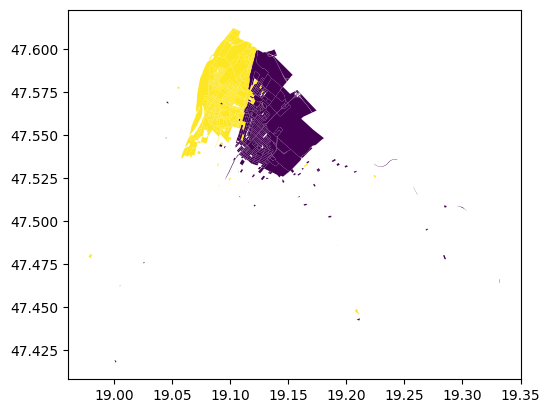

In [8]:
comm.query("community.isin([14,15]) ").plot(column="community")

In [10]:
mc = gpd.read_file("../data/louvain_r2.5_merged.geojson")

<Axes: >

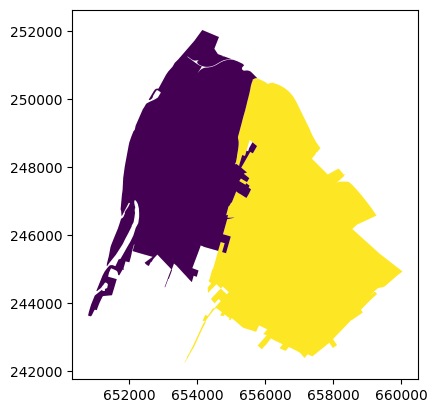

In [15]:
mc.query("id.isin([18,24]) ").plot(column="id")

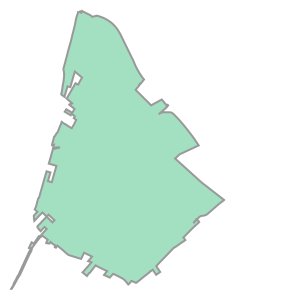

<Axes: >

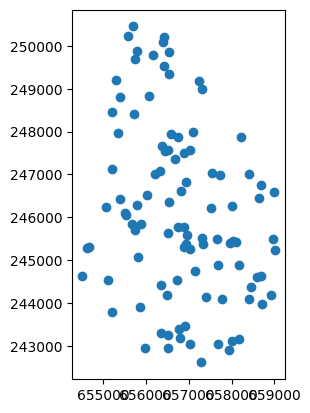

In [36]:
# np.random.seed(11)
mc.query("id==24")["geometry"].sample_points(size=100, rng=10).plot()

In [46]:
c18_mp = mc.query("id==18")["geometry"].sample_points(size=100, rng=10)
c18 = [i for i in c18_mp.values[0].geoms]

c24_mp = mc.query("id==24")["geometry"].sample_points(size=100, rng=10)
c24 = [i for i in c24_mp.values[0].geoms]

In [53]:
nodes18 = gpd.GeoDataFrame({"id": list(range(1800, 1900))}, geometry=c18, crs=23700)
nodes24 = gpd.GeoDataFrame({"id": list(range(2400, 2500))}, geometry=c24, crs=23700)

In [75]:
nodes18["lon"] = nodes18["geometry"].centroid.x
nodes18["lat"] = nodes18["geometry"].centroid.y
nodes24["lon"] = nodes24["geometry"].centroid.x
nodes24["lat"] = nodes24["geometry"].centroid.y

In [82]:
node_loc18 = nodes18.set_index("id").to_dict(orient="index")
node_loc24 = nodes24.set_index("id").to_dict(orient="index")
pos18 = {k: [v["lon"], v["lat"]] for k, v in node_loc18.items()}
pos24 = {k: [v["lon"], v["lat"]] for k, v in node_loc24.items()}

In [71]:
g24b = nx.barabasi_albert_graph(100, 5, seed=24)
g18b = nx.barabasi_albert_graph(100, 5, seed=18)

In [61]:
g18 = nx.watts_strogatz_graph(100, 6, 0.64, seed=17)
g24 = nx.watts_strogatz_graph(100, 8, 0.68, seed=11)

In [88]:
g18b = nx.relabel_nodes(g18b, {o: n for o, n in enumerate(range(1800, 1900))})
g24b = nx.relabel_nodes(g24b, {o: n for o, n in enumerate(range(2400, 2500))})

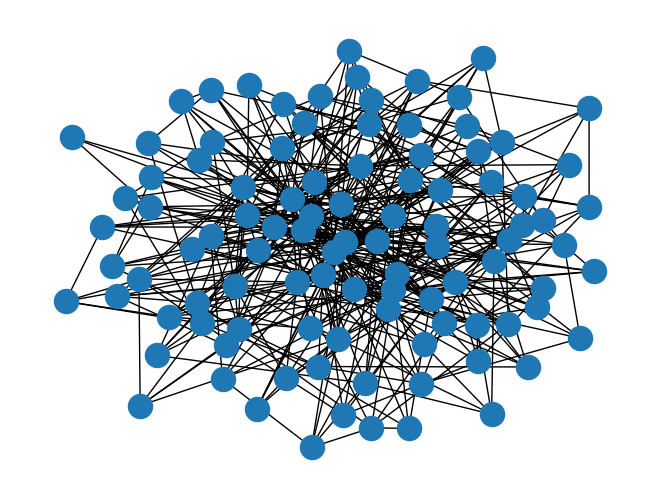

In [72]:
nx.draw(g24b)

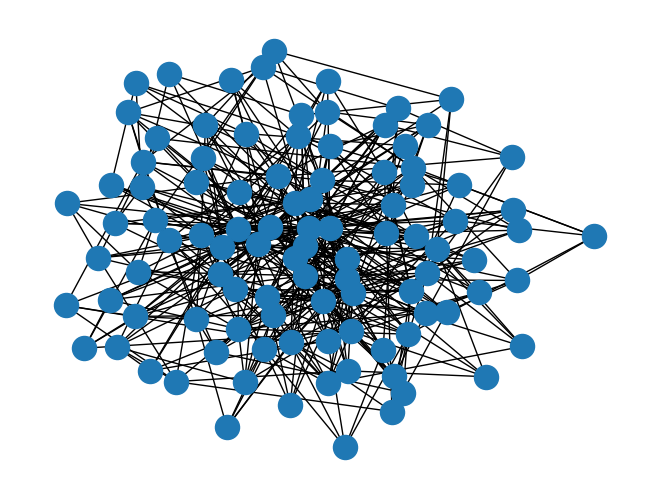

In [73]:
nx.draw(g18b)

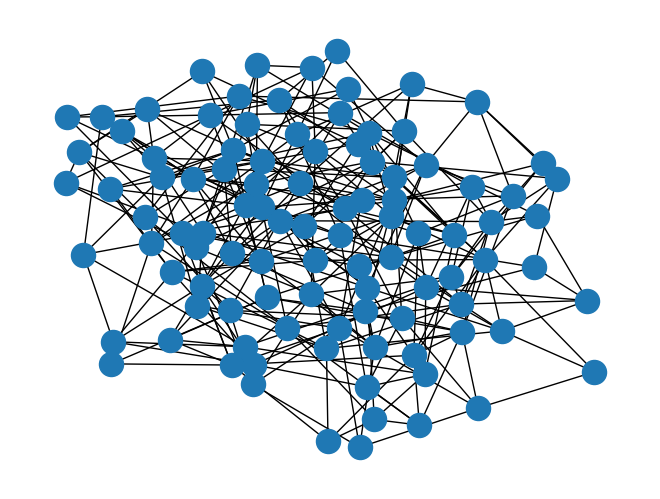

In [62]:
nx.draw(g18)

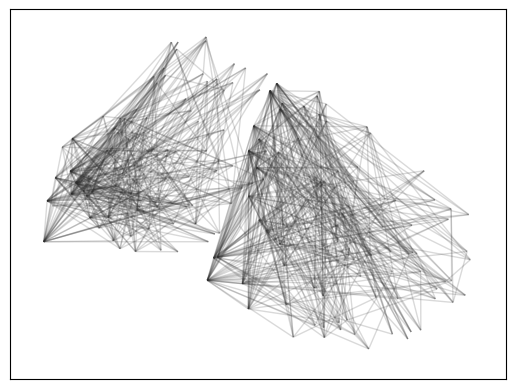

In [95]:
fig, ax = plt.subplots()
nx.draw_networkx(
    g18b,
    pos=pos18,
    with_labels=False,
    edgecolors="white",
    # linewidths=nbw,
    linewidths=0,
    # node_size=ns,
    # node_color=nc,
    node_color="none",
    # width=ew,
    edge_color="#2d2d2d2d",
    # cmap=cmap,
    ax=ax,
)
nx.draw_networkx(
    g24b,
    pos=pos24,
    with_labels=False,
    edgecolors="white",
    # linewidths=nbw,
    linewidths=0,
    # node_size=ns,
    # node_color=nc,
    node_color="none",
    # width=ew,
    edge_color="#2d2d2d2d",
    # cmap=cmap,
    ax=ax,
)

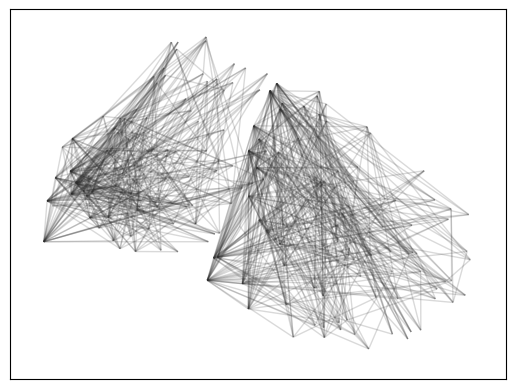

In [96]:
fig